# Espectrograma de una clase

Etapa 2 de `plan_python.md`. Muestra cómo cambia el espectro de cada toma que quedó en la carpeta. No usa `firma.ipynb`.

Lee los `.raw` de `carpeta/outputs/`. Para cambiar de clase, editá `CARPETA` y volvé a correr desde ahí. Los valores son `grabacion/parche`, `grabacion/anillo` y `grabacion/ambiente`.

El cálculo es una STFT con NumPy: ventana de Hann, FFT y potencia. Matplotlib solo dibuja. NumPy es la referencia que después tiene que repetir `esp-dsp`. La FFT es de 512 muestras, potencia de 2, porque `esp-dsp` usa FFT radix-2. A 16 000 Hz, 512 muestras son 32 ms. Los 30 ms del plan son 480 muestras y no entran en esa FFT. El salto es 256 muestras, 16 ms, la mitad de la ventana. Esas dos cifras son de esta vista. La etapa 4 las vuelve a anotar como parámetros del modelo.

Cada bin de frecuencia mide `16000 / 512` Hz, o sea 31,25 Hz. El eje llega hasta 8 000 Hz.

El color es potencia en dB respecto del pico de esa toma. 0 dB es lo más fuerte del archivo. Cerca de −80 dB queda oscuro. Un golpe al parche o al anillo se ve como una barra vertical. El ambiente se ve más estable a lo largo del tiempo.

El kernel tiene que ser el Python de `tinyml`: `C:\Users\angel\miniconda3\envs\tinyml\python.exe`.


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

FRECUENCIA_HZ = 16000
N_FFT = 512
SALTO = 256
#CARPETA = "grabacion/parche"
CARPETA = "grabacion/anillo"


def resolver_carpeta(texto):
    ruta = Path(texto)
    if ruta.is_dir():
        return ruta
    desde_pruebas = Path("pruebas_py") / texto
    if desde_pruebas.is_dir():
        return desde_pruebas
    raise FileNotFoundError(texto)


carpeta = resolver_carpeta(CARPETA)
clase = carpeta.name
raws = sorted((carpeta / "outputs").glob("*.raw"))
if not raws:
    raise FileNotFoundError("no hay .raw en %s" % (carpeta / "outputs"))

tomas = []
for ruta in raws:
    pcm = np.fromfile(ruta, dtype="<i2")
    tomas.append({"nombre": ruta.stem, "pcm": pcm})

print("clase:", clase)
print("carpeta:", carpeta)
print("tomas:", len(tomas))
print("ventana:", N_FFT, "muestras,", 1000.0 * N_FFT / FRECUENCIA_HZ, "ms")
print("salto:", SALTO, "muestras,", 1000.0 * SALTO / FRECUENCIA_HZ, "ms")
print("bin:", FRECUENCIA_HZ / N_FFT, "Hz")


clase: anillo
carpeta: grabacion\anillo
tomas: 28
ventana: 512 muestras, 32.0 ms
salto: 256 muestras, 16.0 ms
bin: 31.25 Hz


## Cada toma

El tiempo va en el eje horizontal y la frecuencia en el vertical. La barra del golpe aparece en el instante del ataque y ocupa varias bandas a la vez. Si una toma aceptada no tiene esa barra, o el ambiente muestra un golpe aislado, conviene anotarla antes de armar las particiones.


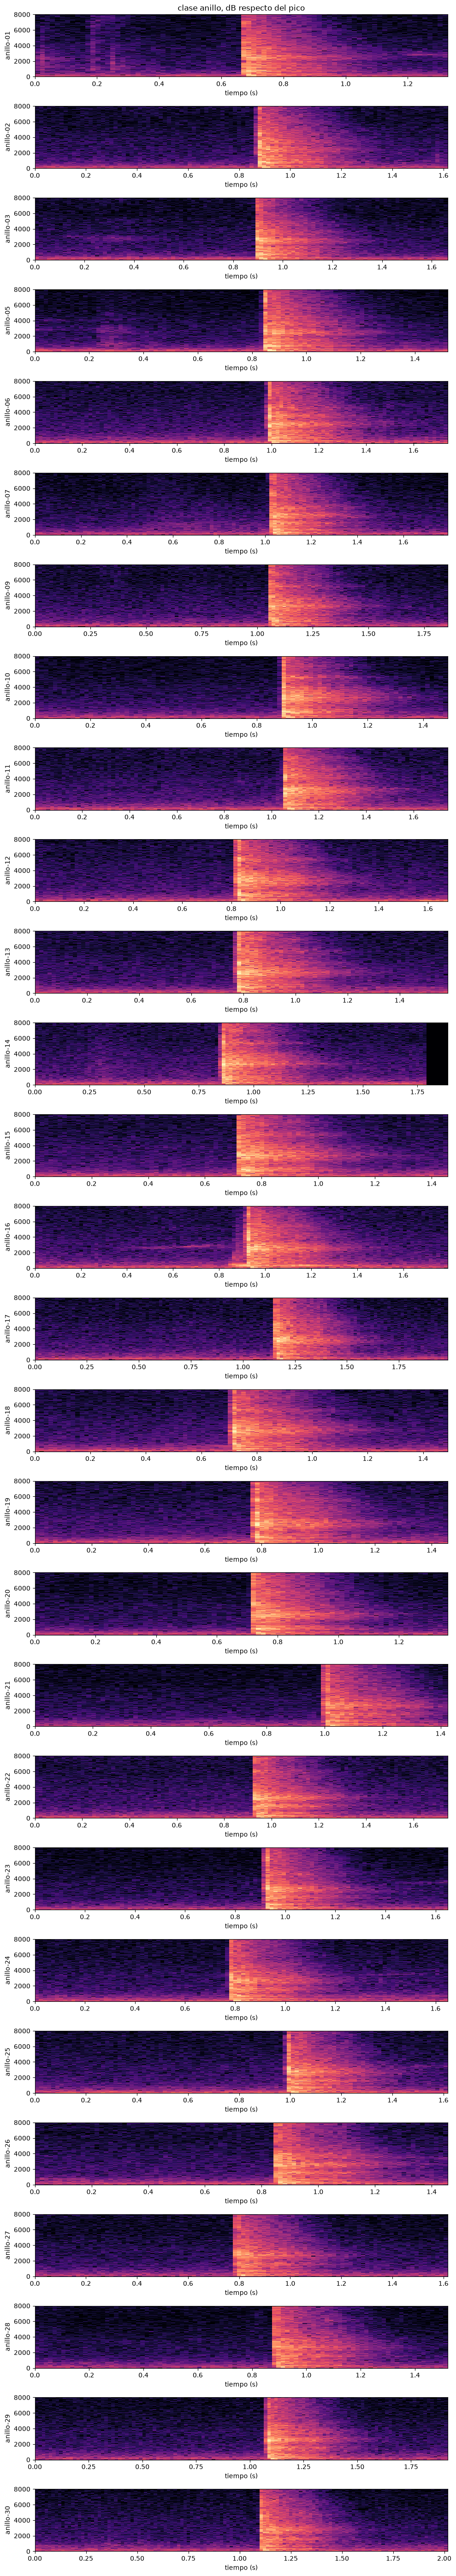

In [4]:
def stft_potencia(pcm):
    x = pcm.astype(np.float64)
    if x.size <= N_FFT:
        n_tramas = 1
    else:
        n_tramas = 1 + (x.size - N_FFT) // SALTO
    largo = (n_tramas - 1) * SALTO + N_FFT
    if x.size < largo:
        x = np.pad(x, (0, largo - x.size))
    ventana = np.hanning(N_FFT)
    potencia = np.empty((N_FFT // 2 + 1, n_tramas))
    for i in range(n_tramas):
        a = i * SALTO
        trama = x[a : a + N_FFT] * ventana
        potencia[:, i] = np.abs(np.fft.rfft(trama)) ** 2
    return potencia


filas = len(tomas)
fig, axes = plt.subplots(filas, 1, figsize=(10, 2.0 * filas), squeeze=False)

for i, toma in enumerate(tomas):
    potencia = stft_potencia(toma["pcm"])
    db = 10.0 * np.log10(potencia / potencia.max() + 1e-12)
    n_tramas = db.shape[1]
    t_fin = ((n_tramas - 1) * SALTO + N_FFT) / FRECUENCIA_HZ
    axes[i, 0].imshow(
        db,
        origin="lower",
        aspect="auto",
        extent=[0, t_fin, 0, FRECUENCIA_HZ / 2],
        vmin=-80,
        vmax=0,
        cmap="magma",
        interpolation="nearest",
    )
    axes[i, 0].set_ylabel(toma["nombre"])
    axes[i, 0].set_xlabel("tiempo (s)")

axes[0, 0].set_title("clase %s, dB respecto del pico" % clase)
fig.tight_layout()
plt.show()
